### 1. Téléchargement et préparation des données
Nous téléchargeons le dataset `flower_photos` depuis TensorFlow et créons les datasets d'entraînement et de validation en appliquant un redimensionnement à 160x160 pixels.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os
import tensorflow as tf

dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
base_dir = tf.keras.utils.get_file('flower_photos', origin=dataset_url, untar=True)
data_dir = os.path.join(base_dir, 'flower_photos')

BATCH_SIZE = 32
IMG_SIZE = (160, 160)

# Dataset d'entraînement (80%)
train_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="training",
  seed=42,
  image_size=IMG_SIZE,
  batch_size=BATCH_SIZE
)

# Dataset de validation (20%)
val_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="validation",
  seed=42,
  image_size=IMG_SIZE,
  batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
print("Classes détectées :", class_names)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Classes détectées : ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


### 2. Visualisation des exemples d'images
Affichons quelques exemples du jeu de données pour vérifier le chargement.

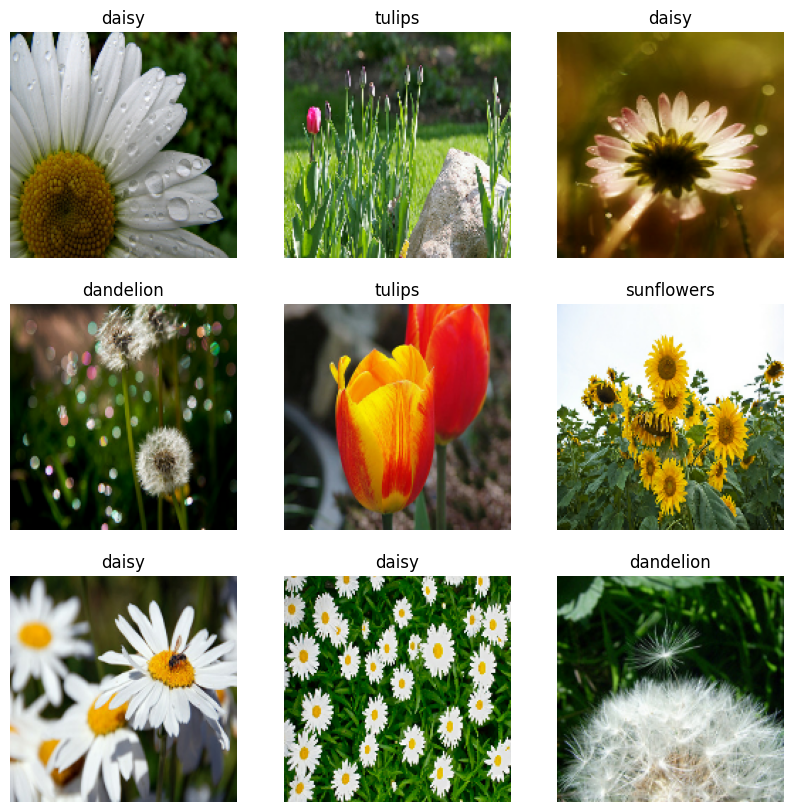

In [ ]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")
plt.show()

### 3. Répartition des classes

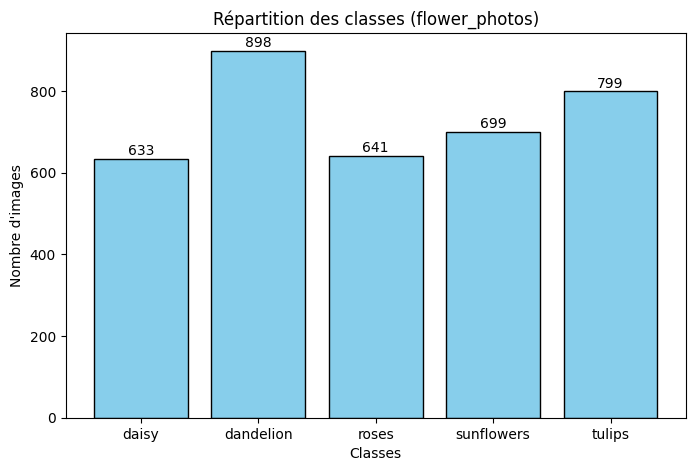

In [ ]:
class_counts = {}
for class_name in class_names:
    class_path = os.path.join(data_dir, class_name)
    # Filtrer pour ne compter que les fichiers (images)
    class_counts[class_name] = len([f for f in os.listdir(class_path) if os.path.isfile(os.path.join(class_path, f))])

# Visualisation sous forme d'un graphique à barres
plt.figure(figsize=(8, 5))
plt.bar(class_counts.keys(), class_counts.values(), color='skyblue', edgecolor='black')
plt.title("Répartition des classes (flower_photos)")
plt.xlabel("Classes")
plt.ylabel("Nombre d'images")
for index, value in enumerate(class_counts.values()):
    plt.text(index, value + 10, str(value), ha='center')
plt.show()

### 4. Entraînement d'un CNN à partir de zéro avec augmentation de données
Nous définissons ici un pipeline d'augmentation de données ainsi qu'un modèle CNN personnalisé (contenant des couches de Convolution, Max Pooling et Dropout).

In [ ]:
from tensorflow.keras import layers, models

# Pipeline d'augmentation de données
data_augmentation = tf.keras.Sequential([
  layers.RandomFlip("horizontal_and_vertical"),
  layers.RandomRotation(0.2),
  layers.RandomZoom(0.2),
])

# Définition de l'architecture du CNN
num_classes = len(class_names)

model = models.Sequential([
  # Augmentation de données appliquée en entrée
  layers.Input(shape=(160, 160, 3)),
  data_augmentation,

  # Normalisation des pixels de [0, 255] à [0, 1]
  layers.Rescaling(1./255),

  # Premier bloc de convolution
  layers.Conv2D(32, (3, 3), activation='relu'),
  layers.MaxPooling2D((2, 2)),

  # Deuxième bloc
  layers.Conv2D(64, (3, 3), activation='relu'),
  layers.MaxPooling2D((2, 2)),

  # Troisième bloc
  layers.Conv2D(128, (3, 3), activation='relu'),
  layers.MaxPooling2D((2, 2)),

  # Quatrième bloc
  layers.Conv2D(128, (3, 3), activation='relu'),
  layers.MaxPooling2D((2, 2)),

  # Passage en vecteur plat (Flatten) et classification
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dropout(0.5), # Dropout pour limiter le surapprentissage
  layers.Dense(num_classes)
])

# Compilation du modèle
model.compile(
  optimizer='adam',
  loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
  metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,290,181 (4.92 MB)

 Trainable params: 1,290,181 (4.92 MB)

 Non-trainable params: 0 (0.00 B)

### 5. Lancement de l'entraînement
Nous allons entraîner le modèle sur 20 époques afin d'observer la courbe de convergence.

In [ ]:
epochs = 20
history = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=epochs
)

Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 227s 2s/step - accuracy: 0.3437 - loss: 1.4356 - val_accuracy: 0.4482 - val_loss: 1.2943
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 215s 2s/step - accuracy: 0.4976 - loss: 1.1779 - val_accuracy: 0.5640 - val_loss: 1.0438
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 263s 2s/step - accuracy: 0.5671 - loss: 1.0553 - val_accuracy: 0.6199 - val_loss: 0.9738
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 254s 2s/step - accuracy: 0.6001 - loss: 0.9869 - val_accuracy: 0.6553 - val_loss: 0.9236
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 268s 2s/step - accuracy: 0.6304 - loss: 0.9381 - val_accuracy: 0.6703 - val_loss: 0.8863
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 214s 2s/step - accuracy: 0.6536 - loss: 0.8841 - val_accuracy: 0.6676 - val_loss: 0.8526
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 264s 2s/step - accuracy: 0.6628 - loss: 0.8874 - val_accuracy: 0.6662 - val_loss: 0.8291
Epoch 8/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 270s 2s/step - accuracy: 0.6693 - loss: 0.8567 - val_accuracy: 0.6907 - v

### 6. Évaluation et visualisation des résultats
Tracer l'évolution de la précision (accuracy) et de la perte (loss) au fil des époques.

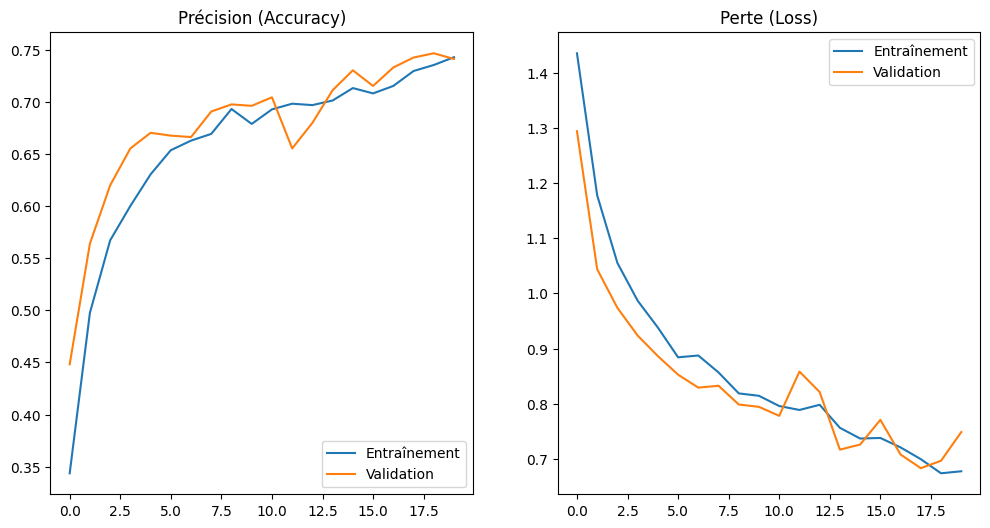

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(epochs)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Entraînement')
plt.plot(epochs_range, val_acc, label='Validation')
plt.legend(loc='lower right')
plt.title('Précision (Accuracy)')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Entraînement')
plt.plot(epochs_range, val_loss, label='Validation')
plt.legend(loc='upper right')
plt.title('Perte (Loss)')
plt.show()

### 7. Extraction de caractéristiques avec MobileNetV2
Nous utilisons MobileNetV2 pré-entraîné sur ImageNet comme extracteur de caractéristiques figé, complété par les couches de classification demandées.

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import Sequential, layers

# Taille d'entrée attendue par notre jeu de données (160, 160, 3)
IMG_SHAPE = IMG_SIZE + (3,)

# Chargement de MobileNetV2 sans la couche de classification finale, et avec les poids ImageNet
base_model = MobileNetV2(input_shape=IMG_SHAPE,
                         include_top=False,
                         weights='imagenet')

# Gel du modèle de base pour l'extraction de caractéristiques
base_model.trainable = False

# Définition du modèle complet avec l'augmentation de données, le pré-traitement spécifique à MobileNetV2 et la tête de classification
fe_model = Sequential([
  layers.Input(shape=IMG_SHAPE),
  data_augmentation,
  # MobileNetV2 attend des valeurs de pixels dans l'intervalle [-1, 1]
  layers.Lambda(tf.keras.applications.mobilenet_v2.preprocess_input),
  base_model,
  layers.GlobalAveragePooling2D(),
  layers.Dropout(0.2),
  layers.Dense(num_classes, activation='softmax')
])

# Compilation du modèle
fe_model.compile(
  optimizer='adam',
  loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
  metrics=['accuracy']
)

# Affichage de l'architecture et du nombre de paramètres
fe_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 8. Entraînement initial de l'extraction de caractéristiques
Avant de dégeler les couches du modèle de base, nous devons entraîner la tête de classification afin d'éviter que ses gradients aléatoires de départ n'endommagent les poids pré-entraînés du modèle de base.

In [ ]:
initial_epochs = 10
history_fe = fe_model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=initial_epochs
)

Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 111s 1s/step - accuracy: 0.6172 - loss: 0.9879 - val_accuracy: 0.8106 - val_loss: 0.5450
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 99s 1s/step - accuracy: 0.8055 - loss: 0.5354 - val_accuracy: 0.8324 - val_loss: 0.4485
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 104s 1s/step - accuracy: 0.8351 - loss: 0.4653 - val_accuracy: 0.8379 - val_loss: 0.4198
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.8471 - loss: 0.4093 - val_accuracy: 0.8406 - val_loss: 0.4294
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.8508 - loss: 0.4116 - val_accuracy: 0.8460 - val_loss: 0.4033
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 137s 1s/step - accuracy: 0.8665 - loss: 0.3781 - val_accuracy: 0.8474 - val_loss: 0.4253
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 103s 1s/step - accuracy: 0.8723 - loss: 0.3414 - val_accuracy: 0.8433 - val_loss: 0.4109
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.8787 - loss: 0.3283 - val_accuracy: 0.8406 - va

### 9. Configuration du Fine-Tuning
Nous dégelons le modèle de base (`base_model`), puis nous regelons toutes les couches à l'exception des 30 dernières. Nous recompilons ensuite le modèle avec un taux d'apprentissage très faible ($10^{-5}$).

In [ ]:
# Dégeler le modèle de base
base_model.trainable = True

# Geler toutes les couches sauf les 30 dernières du base_model
fine_tune_at = len(base_model.layers) - 30
for layer in base_model.layers[:fine_tune_at]:
  layer.trainable = False

# Recompilation avec un optimizer à faible taux d'apprentissage
fe_model.compile(
  optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
  loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
  metrics=['accuracy']
)

fe_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 1,532,805 (5.85 MB)

 Non-trainable params: 731,584 (2.79 MB)

### 10. Lancement du Fine-Tuning
Nous continuons l'entraînement pour 10 époques supplémentaires (époques 11 à 20).

In [ ]:
fine_tune_epochs = 10
total_epochs = initial_epochs + fine_tune_epochs

history_fine = fe_model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=total_epochs,
  initial_epoch=history_fe.epoch[-1] + 1
)

Epoch 11/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 137s 1s/step - accuracy: 0.7987 - loss: 0.5220 - val_accuracy: 0.8597 - val_loss: 0.3893
Epoch 12/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 126s 1s/step - accuracy: 0.8386 - loss: 0.4251 - val_accuracy: 0.8583 - val_loss: 0.3854
Epoch 13/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.8563 - loss: 0.3878 - val_accuracy: 0.8610 - val_loss: 0.3787
Epoch 14/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 148s 1s/step - accuracy: 0.8641 - loss: 0.3904 - val_accuracy: 0.8665 - val_loss: 0.3753
Epoch 15/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.8743 - loss: 0.3566 - val_accuracy: 0.8665 - val_loss: 0.3760
Epoch 16/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.8845 - loss: 0.3121 - val_accuracy: 0.8719 - val_loss: 0.3703
Epoch 17/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 128s 1s/step - accuracy: 0.8750 - loss: 0.3498 - val_accuracy: 0.8733 - val_loss: 0.3635
Epoch 18/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - accuracy: 0.8808 - loss: 0.3227 - val_accuracy: 0.

### 11. Tracé des courbes d'apprentissage en continu
Nous combinons les historiques d'entraînement pour tracer des courbes d'apprentissage continues montrant la transition entre l'extraction de caractéristiques et le fine-tuning.

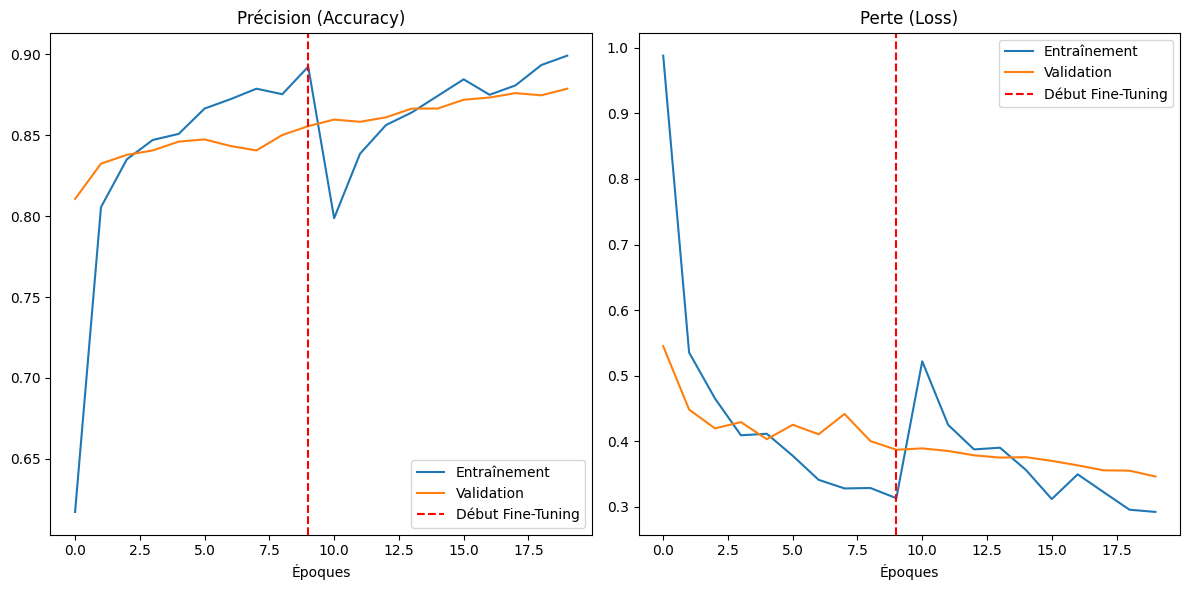

In [ ]:
# Combinaison des métriques
all_acc = history_fe.history['accuracy'] + history_fine.history['accuracy']
all_val_acc = history_fe.history['val_accuracy'] + history_fine.history['val_accuracy']
all_loss = history_fe.history['loss'] + history_fine.history['loss']
all_val_loss = history_fe.history['val_loss'] + history_fine.history['val_loss']

plt.figure(figsize=(12, 6))

# Graphe de la précision
plt.subplot(1, 2, 1)
plt.plot(all_acc, label="Entraînement")
plt.plot(all_val_acc, label="Validation")
plt.axvline(x=initial_epochs-1, color='red', linestyle='--', label='Début Fine-Tuning')
plt.legend(loc='lower right')
plt.title("Précision (Accuracy)")
plt.xlabel("Époques")

# Graphe de la perte
plt.subplot(1, 2, 2)
plt.plot(all_loss, label="Entraînement")
plt.plot(all_val_loss, label="Validation")
plt.axvline(x=initial_epochs-1, color='red', linestyle='--', label='Début Fine-Tuning')
plt.legend(loc='upper right')
plt.title("Perte (Loss)")
plt.xlabel("Époques")

plt.tight_layout()
plt.show()

### 12. Analyse de l'impact de la taille du jeu d'entraînement
Nous allons entraîner les deux modèles sur des fractions réduites du jeu d'entraînement (5%, 10%, 25%, 50%, 100%) afin de comparer leur robustesse face au manque de données.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Définition des fractions de données à tester
fractions = [0.05, 0.10, 0.25, 0.50, 1.00]

# Listes pour stocker les scores d'accuracy finaux sur le jeu de validation
cnn_val_accuracies = []
fe_val_accuracies = []

# Nombre d'époques d'entraînement rapide pour l'expérience
epochs_exp = 5

for frac in fractions:
    print(f"\n--- Entraînement avec {int(frac * 100)}% des données ---")

    # Échantillonnage de la fraction du dataset d'entraînement
    # train_ds contient 2936 fichiers au total
    num_batches = len(train_ds)
    keep_batches = int(np.ceil(num_batches * frac))
    sampled_train_ds = train_ds.take(keep_batches)

    # 1. Modèle de référence (CNN from scratch)
    # Nous reconstruisons une instance fraîche du CNN
    cnn_model = tf.keras.models.Sequential([
      layers.Input(shape=(160, 160, 3)),
      data_augmentation,
      layers.Rescaling(1./255),
      layers.Conv2D(32, (3, 3), activation='relu'),
      layers.MaxPooling2D((2, 2)),
      layers.Conv2D(64, (3, 3), activation='relu'),
      layers.MaxPooling2D((2, 2)),
      layers.Flatten(),
      layers.Dense(128, activation='relu'),
      layers.Dropout(0.5),
      layers.Dense(num_classes)
    ])

    cnn_model.compile(
      optimizer='adam',
      loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
      metrics=['accuracy']
    )

    cnn_model.fit(sampled_train_ds, validation_data=val_ds, epochs=epochs_exp, verbose=0)
    _, cnn_acc = cnn_model.evaluate(val_ds, verbose=0)
    cnn_val_accuracies.append(cnn_acc)
    print(f"CNN From Scratch - Val Accuracy: {cnn_acc:.4f}")

    # 2. Modèle par extraction de caractéristiques (MobileNetV2)
    # Nous figeons à nouveau le base_model
    base_model.trainable = False

    fe_model_exp = tf.keras.Sequential([
      layers.Input(shape=IMG_SHAPE),
      data_augmentation,
      layers.Lambda(tf.keras.applications.mobilenet_v2.preprocess_input),
      base_model,
      layers.GlobalAveragePooling2D(),
      layers.Dropout(0.2),
      layers.Dense(num_classes, activation='softmax')
    ])

    fe_model_exp.compile(
      optimizer='adam',
      loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
      metrics=['accuracy']
    )

    fe_model_exp.fit(sampled_train_ds, validation_data=val_ds, epochs=epochs_exp, verbose=0)
    _, fe_acc = fe_model_exp.evaluate(val_ds, verbose=0)
    fe_val_accuracies.append(fe_acc)
    print(f"Extraction de caractéristiques (MobileNetV2) - Val Accuracy: {fe_acc:.4f}")


--- Entraînement avec 5% des données ---
CNN From Scratch - Val Accuracy: 0.1540
Extraction de caractéristiques (MobileNetV2) - Val Accuracy: 0.7316

--- Entraînement avec 10% des données ---
CNN From Scratch - Val Accuracy: 0.3678
Extraction de caractéristiques (MobileNetV2) - Val Accuracy: 0.8038

--- Entraînement avec 25% des données ---
CNN From Scratch - Val Accuracy: 0.5313
Extraction de caractéristiques (MobileNetV2) - Val Accuracy: 0.8460

--- Entraînement avec 50% des données ---
CNN From Scratch - Val Accuracy: 0.5940
Extraction de caractéristiques (MobileNetV2) - Val Accuracy: 0.8638

--- Entraînement avec 100% des données ---
CNN From Scratch - Val Accuracy: 0.6172
Extraction de caractéristiques (MobileNetV2) - Val Accuracy: 0.8624


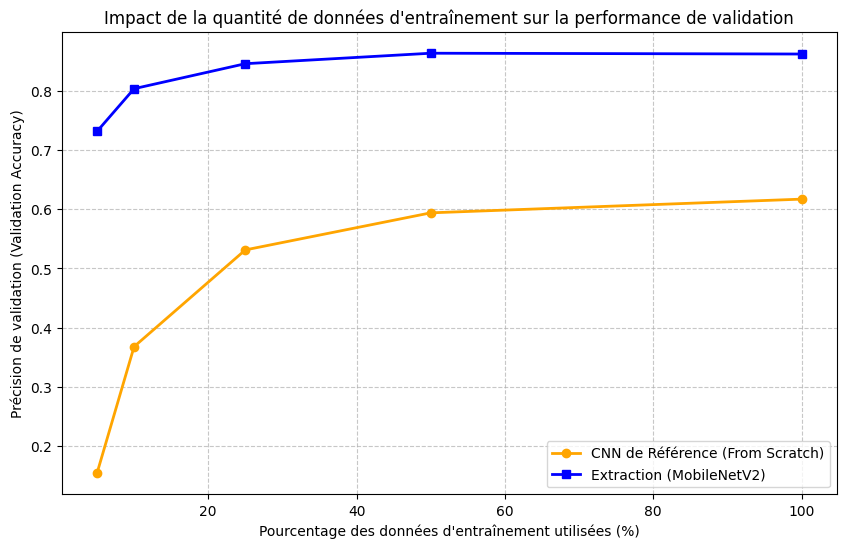

In [ ]:
# Tracer l'évolution de la précision de validation selon la taille des données
plt.figure(figsize=(10, 6))
plt.plot([f * 100 for f in fractions], cnn_val_accuracies, marker='o', label='CNN de Référence (From Scratch)', color='orange', linewidth=2)
plt.plot([f * 100 for f in fractions], fe_val_accuracies, marker='s', label='Extraction (MobileNetV2)', color='blue', linewidth=2)
plt.title("Impact de la quantité de données d'entraînement sur la performance de validation")
plt.xlabel("Pourcentage des données d'entraînement utilisées (%)")
plt.ylabel("Précision de validation (Validation Accuracy)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.show()

### Conclusion

Après analyse du graphe d'apprentissage, on observe ce qui suit:

- L'augmentation des données d'entrainement conduit à une augmentation de l'accuracy pour les deux modèles.

- Toutefois, on constate que l'accuracy du modèle par extraction(MobileNetV2) est déjà bien élevé dès le début(73%) malgré la faible quantité de données d'entrainement(5%)

- Et avec 100% des données d'apprentissage disponible, le modele par extraction de caractéristiques garde des score beaucoup plus élevé que le modèle qui a appris from scratch

**On peut donc conclure que pour ce projet, la meilleur solution serait d'utiliser le model d'extraction de caractéristiques fine tunné plutôt qu'un modèle entrainé from scratch sur les données d'entrainement disponible**

In [ ]:
fe_model_without_preprocess = Sequential([
  layers.Input(shape=IMG_SHAPE),
  data_augmentation,
  base_model,
  layers.GlobalAveragePooling2D(),
  layers.Dropout(0.2),
  layers.Dense(num_classes, activation='softmax')
])

# Compilation du modèle
fe_model_without_preprocess.compile(
  optimizer='adam',
  loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
  metrics=['accuracy']
)

initial_epochs = 10
history_fe_without_preprocess = fe_model_without_preprocess.fit(
  train_ds,
  validation_data=val_ds,
  epochs=initial_epochs
)

Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 109s 1s/step - accuracy: 0.4005 - loss: 1.5082 - val_accuracy: 0.5409 - val_loss: 1.1935
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.5341 - loss: 1.1972 - val_accuracy: 0.5831 - val_loss: 1.1531
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 146s 1s/step - accuracy: 0.5811 - loss: 1.0974 - val_accuracy: 0.5981 - val_loss: 1.0672
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 104s 1s/step - accuracy: 0.5933 - loss: 1.0804 - val_accuracy: 0.6090 - val_loss: 1.0231
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - accuracy: 0.6049 - loss: 1.0375 - val_accuracy: 0.6090 - val_loss: 1.0172
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.6161 - loss: 1.0195 - val_accuracy: 0.6267 - val_loss: 0.9731
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.6097 - loss: 1.0054 - val_accuracy: 0.6131 - val_loss: 1.0169
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step - accuracy: 0.6155 - loss: 0.9995 - val_accuracy: 0.6158 - v

### Commentaire

- Avec preprocess_input (Précision de validation : ~85.5% à l'époque 10)

- Sans preprocess_input (Précision de validation : ~62.6% à l'époque 10)

### Conclusion

Lors de l'utilisation d'un modèle pré-entraîné, il faut impérativement appliquer exactement le même prétraitement (mise à l'échelle, centrage) que celui utilisé lors de l'entraînement initial du modèle (ici ImageNet pour MobileNetV2). Omettre cette étape fait perdre les bénéfices des poids pré-entraînés.